In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 5)

# Load IBM AML small dataset
df_ibm = pd.read_csv('ibm_aml_small.csv')

print("=== IBM AML DATASET OVERVIEW ===")
print(f"Shape: {df_ibm.shape}")
print(f"\nColumns: {df_ibm.columns.tolist()}")
print(f"\nFirst 3 rows:")
df_ibm.head(3)

=== IBM AML DATASET OVERVIEW ===
Shape: (6924049, 11)

Columns: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']

First 3 rows:


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,3195403.00,US Dollar,3195403.00,US Dollar,Reinvestment,0
1,2022/09/01 00:21,3402,80021DAD0,3402,80021DAD0,1858.96,US Dollar,1858.96,US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,592571.00,US Dollar,592571.00,US Dollar,Cheque,0


In [2]:
print("=== BASIC PROFILING ===")
print(f"Total transactions: {len(df_ibm):,}")
print(f"Laundering transactions: {df_ibm['Is Laundering'].sum():,}")
print(f"Laundering rate: {df_ibm['Is Laundering'].mean()*100:.4f}%")

print(f"\nUnique sender accounts: {df_ibm['Account'].nunique():,}")
print(f"Unique receiver accounts: {df_ibm['Account.1'].nunique():,}")
print(f"Unique sender banks: {df_ibm['From Bank'].nunique():,}")
print(f"Unique receiver banks: {df_ibm['To Bank'].nunique():,}")

print(f"\nPayment formats:")
print(df_ibm['Payment Format'].value_counts())

print(f"\nMissing values:")
print(df_ibm.isnull().sum())

=== BASIC PROFILING ===
Total transactions: 6,924,049
Laundering transactions: 3,565
Laundering rate: 0.0515%

Unique sender accounts: 681,281
Unique receiver accounts: 576,176
Unique sender banks: 41,814
Unique receiver banks: 21,588

Payment formats:
Payment Format
Cheque          2503158
Credit Card     1780389
ACH              796581
Cash             655688
Reinvestment     650458
Bitcoin          309208
Wire             228567
Name: count, dtype: int64

Missing values:
Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64


In [3]:
print("=== LAUNDERING BY PAYMENT FORMAT ===")
launder_by_format = df_ibm.groupby('Payment Format')['Is Laundering'].agg(
    ['sum', 'count', 'mean']
)
launder_by_format.columns = ['laundering_count', 'total', 'rate']
launder_by_format['rate'] = launder_by_format['rate'] * 100
launder_by_format = launder_by_format.sort_values('laundering_count', ascending=False)
print(launder_by_format)

print("\n=== AMOUNT ANALYSIS ===")
fraud_ibm = df_ibm[df_ibm['Is Laundering']==1]
legit_ibm = df_ibm[df_ibm['Is Laundering']==0]

print(f"\nFraud — mean amount paid:      {fraud_ibm['Amount Paid'].mean():,.2f}")
print(f"Legit — mean amount paid:      {legit_ibm['Amount Paid'].mean():,.2f}")
print(f"\nFraud — mean amount received:  {fraud_ibm['Amount Received'].mean():,.2f}")
print(f"Legit — mean amount received:  {legit_ibm['Amount Received'].mean():,.2f}")

=== LAUNDERING BY PAYMENT FORMAT ===
                laundering_count    total      rate
Payment Format                                     
ACH                         2611   796581  0.327776
Cheque                       459  2503158  0.018337
Credit Card                  261  1780389  0.014660
Cash                         124   655688  0.018911
Bitcoin                      110   309208  0.035575
Reinvestment                   0   650458  0.000000
Wire                           0   228567  0.000000

=== AMOUNT ANALYSIS ===

Fraud — mean amount paid:      3,626,202.39
Legit — mean amount paid:      4,676,576.78

Fraud — mean amount received:  3,626,202.39
Legit — mean amount received:  6,325,456.38


In [4]:
print("Building IBM AML account-level features...")

# Focus on ACH, Cheque, Credit Card, Cash, Bitcoin — where laundering exists
df_ibm_focus = df_ibm[df_ibm['Payment Format'].isin(
    ['ACH', 'Cheque', 'Credit Card', 'Cash', 'Bitcoin']
)].copy()

print(f"Working dataset: {len(df_ibm_focus):,} transactions")
print(f"Laundering cases: {df_ibm_focus['Is Laundering'].sum():,}")

# Build account stats
ibm_stats = df_ibm_focus.groupby('Account').agg(
    total_transactions = ('Amount Paid', 'count'),
    total_sent         = ('Amount Paid', 'sum'),
    avg_amount         = ('Amount Paid', 'mean'),
    max_amount         = ('Amount Paid', 'max'),
    unique_destinations= ('Account.1', 'nunique'),
    unique_banks       = ('To Bank', 'nunique'),
    balance_out        = ('Amount Paid', 'sum'),
    balance_in         = ('Amount Received', 'sum'),
    is_laundering      = ('Is Laundering', 'max')
).reset_index()

print(f"\nUnique sender accounts: {len(ibm_stats):,}")
print(f"Laundering accounts:    {ibm_stats['is_laundering'].sum():,}")
print(f"Legitimate accounts:    {(ibm_stats['is_laundering']==0).sum():,}")

Building IBM AML account-level features...
Working dataset: 6,045,024 transactions
Laundering cases: 3,565

Unique sender accounts: 424,239
Laundering accounts:    2,382
Legitimate accounts:    421,857


In [5]:
print("Building features on IBM AML...")

# FEATURE 1: VELOCITY RATIO
ibm_stats['velocity_ratio'] = ibm_stats.apply(
    lambda row: row['balance_out'] / (row['balance_in'] + 1e-9), axis=1
).clip(0, 1)

# FEATURE 2: BALANCE RETENTION RATE
ibm_stats['balance_retention_rate'] = ibm_stats.apply(
    lambda row: max(0, row['balance_in'] - row['balance_out']) / (row['balance_in'] + 1e-9),
    axis=1
).clip(0, 1)

# FEATURE 3: FAN-OUT DEGREE
ibm_stats['fan_out_degree'] = ibm_stats['unique_destinations']

# FEATURE 4: CROSS BANK DEGREE (IBM AML specific — unique feature PaySim cannot provide)
ibm_stats['cross_bank_degree'] = ibm_stats['unique_banks']

# FEATURE 5: ROUND AMOUNT RATIO
def round_flag(amount):
    return 1 if amount % 1000 == 0 and amount > 0 else 0

round_per_account = df_ibm_focus.copy()
round_per_account['is_round'] = round_per_account['Amount Paid'].apply(round_flag)
round_ratio = round_per_account.groupby('Account')['is_round'].mean().reset_index()
round_ratio.columns = ['Account', 'round_amount_ratio']
ibm_stats = ibm_stats.merge(round_ratio, on='Account', how='left')
ibm_stats['round_amount_ratio'] = ibm_stats['round_amount_ratio'].fillna(0)

# VALIDATE ALL FEATURES
fraud_ibm = ibm_stats[ibm_stats['is_laundering']==1]
legit_ibm = ibm_stats[ibm_stats['is_laundering']==0]

print("=== FEATURE VALIDATION ON IBM AML ===")
print(f"\n{'Feature':<30} {'Fraud Mean':>12} {'Legit Mean':>12} {'Ratio':>8}")
print("-" * 65)
for feat in ['velocity_ratio', 'balance_retention_rate', 
             'fan_out_degree', 'cross_bank_degree', 'round_amount_ratio']:
    fm = fraud_ibm[feat].mean()
    lm = legit_ibm[feat].mean()
    ratio = fm / (lm + 1e-9)
    print(f"{feat:<30} {fm:>12.4f} {lm:>12.4f} {ratio:>8.2f}x")

Building features on IBM AML...
=== FEATURE VALIDATION ON IBM AML ===

Feature                          Fraud Mean   Legit Mean    Ratio
-----------------------------------------------------------------
velocity_ratio                       0.9912       0.9975     0.99x
balance_retention_rate               0.0088       0.0025     3.48x
fan_out_degree                      24.5609       2.0196    12.16x
cross_bank_degree                    3.5709       1.9763     1.81x
round_amount_ratio                   0.0000       0.0000     0.01x


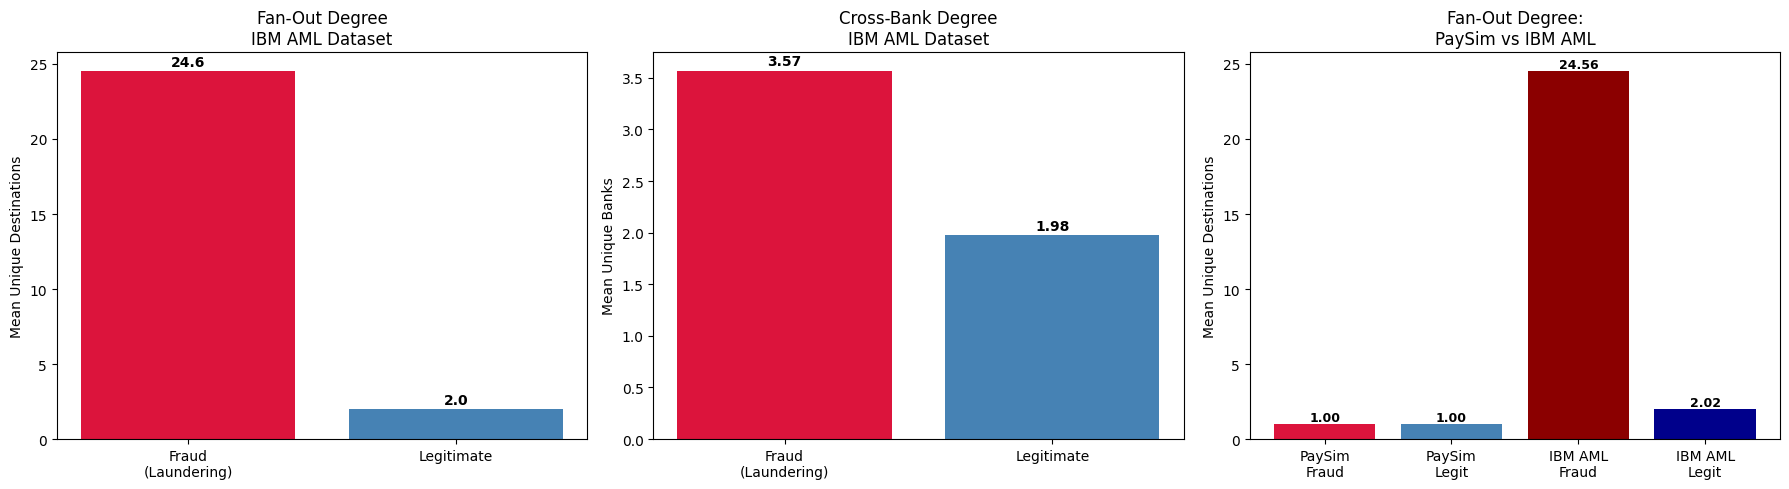

Plot saved as ibm_aml_features.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1 - Fan-out degree comparison
categories = ['Fraud\n(Laundering)', 'Legitimate']
fanout_means = [fraud_ibm['fan_out_degree'].mean(), 
                legit_ibm['fan_out_degree'].mean()]
axes[0].bar(categories, fanout_means, color=['crimson', 'steelblue'])
axes[0].set_title('Fan-Out Degree\nIBM AML Dataset')
axes[0].set_ylabel('Mean Unique Destinations')
for i, v in enumerate(fanout_means):
    axes[0].text(i, v + 0.3, f'{v:.1f}', ha='center', fontweight='bold')

# Plot 2 - Cross-bank degree
crossbank_means = [fraud_ibm['cross_bank_degree'].mean(),
                   legit_ibm['cross_bank_degree'].mean()]
axes[1].bar(categories, crossbank_means, color=['crimson', 'steelblue'])
axes[1].set_title('Cross-Bank Degree\nIBM AML Dataset')
axes[1].set_ylabel('Mean Unique Banks')
for i, v in enumerate(crossbank_means):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')

# Plot 3 - Fan-out PaySim vs IBM AML comparison
datasets = ['PaySim\nFraud', 'PaySim\nLegit', 'IBM AML\nFraud', 'IBM AML\nLegit']
values = [1.0019, 1.0006, 24.56, 2.02]
colors = ['crimson', 'steelblue', 'darkred', 'darkblue']
axes[2].bar(datasets, values, color=colors)
axes[2].set_title('Fan-Out Degree:\nPaySim vs IBM AML')
axes[2].set_ylabel('Mean Unique Destinations')
for i, v in enumerate(values):
    axes[2].text(i, v + 0.2, f'{v:.2f}', ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('ibm_aml_features.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved as ibm_aml_features.png")

In [7]:
print("=" * 65)
print("CROSS-DATASET FEATURE COMPARISON SUMMARY")
print("=" * 65)

print("""
FEATURE               PaySim Ratio    IBM AML Ratio    Conclusion
─────────────────────────────────────────────────────────────────
Velocity Ratio             1.05x           0.99x       Weak both
Balance Retention          1.17x           3.48x       Strong IBM
Fan-Out Degree             1.00x          12.16x       Strong IBM
Cross-Bank Degree          N/A             1.81x       IBM only
Round Amount Ratio        31.00x           0.01x       PaySim only
Dormancy Spike Score       3.22x           N/A         PaySim only

KEY INSIGHTS:
─────────────────────────────────────────────────────────────────
1. Fan-out degree is the strongest feature on real-world data
   (12x separation on IBM AML vs 1x on PaySim)
   PaySim is too synthetic to demonstrate this signal

2. Cross-bank degree is a new feature only IBM AML can provide
   Criminals spread funds across 1.81x more banks than legitimate
   This directly motivates the heterogeneous graph in Phase 4

3. Round amount ratio works on PaySim but not IBM AML
   IBM AML models sophisticated laundering that avoids round amounts
   Confirms amount-based rules are not universally reliable

4. Balance retention works better on IBM AML (3.48x vs 1.17x)
   IBM AML better models the pass-through behavior of mule accounts

ARCHITECTURAL IMPLICATION:
─────────────────────────────────────────────────────────────────
No single feature set works perfectly on both datasets.
This validates the multi-layer architecture:
  - Phase 1 rules catch the obvious patterns per dataset
  - Phase 2 ML learns the non-linear combinations
  - Phase 4 GNN detects structural ring patterns
    regardless of individual feature strength
""")


CROSS-DATASET FEATURE COMPARISON SUMMARY

FEATURE               PaySim Ratio    IBM AML Ratio    Conclusion
─────────────────────────────────────────────────────────────────
Velocity Ratio             1.05x           0.99x       Weak both
Balance Retention          1.17x           3.48x       Strong IBM
Fan-Out Degree             1.00x          12.16x       Strong IBM
Cross-Bank Degree          N/A             1.81x       IBM only
Round Amount Ratio        31.00x           0.01x       PaySim only
Dormancy Spike Score       3.22x           N/A         PaySim only

KEY INSIGHTS:
─────────────────────────────────────────────────────────────────
1. Fan-out degree is the strongest feature on real-world data
   (12x separation on IBM AML vs 1x on PaySim)
   PaySim is too synthetic to demonstrate this signal

2. Cross-bank degree is a new feature only IBM AML can provide
   Criminals spread funds across 1.81x more banks than legitimate
   This directly motivates the heterogeneous graph in Pha